# 55. Alternative Visualizations for DO Trends
This notebook explores different ways to visualize the progression of Dissolved Oxygen across different basins, focusing on temporal trends, distributions, and risk assessments.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sys
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Project Path Setup
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths
from scripts.mapping_config import MappingConfig
from scripts.data_loader import load_and_process_data

# Apply global styles
MappingConfig.apply_global_plot_styles()
sns.set_context("notebook", font_scale=1.2)
sns.set_style("whitegrid")

# Load the pre-processed data
merged_gdf = load_and_process_data(force_reload=False)

# Filter for Summer Bottom data
TARGET_SEASON = 'Summer'
SAISUIPOIN_ID = 2

summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == TARGET_SEASON) & 
    (merged_gdf['saisuipoin'] == SAISUIPOIN_ID)
].copy()

summer_bottom_df['do_'] = pd.to_numeric(summer_bottom_df['do_'], errors='coerce')
summer_bottom_df = summer_bottom_df.dropna(subset=['do_', 'year'])

# Create a unified 'basin' column for easier plotting
# (combining watermass_name for Tokyo/Ise and division for Seto Inland Sea)
summer_bottom_df['basin'] = summer_bottom_df['watermass_name']
sis_mask = summer_bottom_df['watermass_name'] == 'Seto Inland Sea'
summer_bottom_df.loc[sis_mask, 'basin'] = summer_bottom_df.loc[sis_mask, 'division']
summer_bottom_df = summer_bottom_df.dropna(subset=['basin'])

print(f"Total observations: {len(summer_bottom_df)}")
print(f"Basins to analyze: {summer_bottom_df['basin'].nunique()}")


Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Total observations: 7644
Basins to analyze: 14


## 1. Time-Series Trend Lines (Basin Averages with Variability)
This plot uses seaborn's `lineplot` to show the annual mean DO for each basin. The shaded area represents the 95% confidence interval of the mean, giving a sense of spatial variability within the basin each year. We use a FacetGrid to separate the basins.


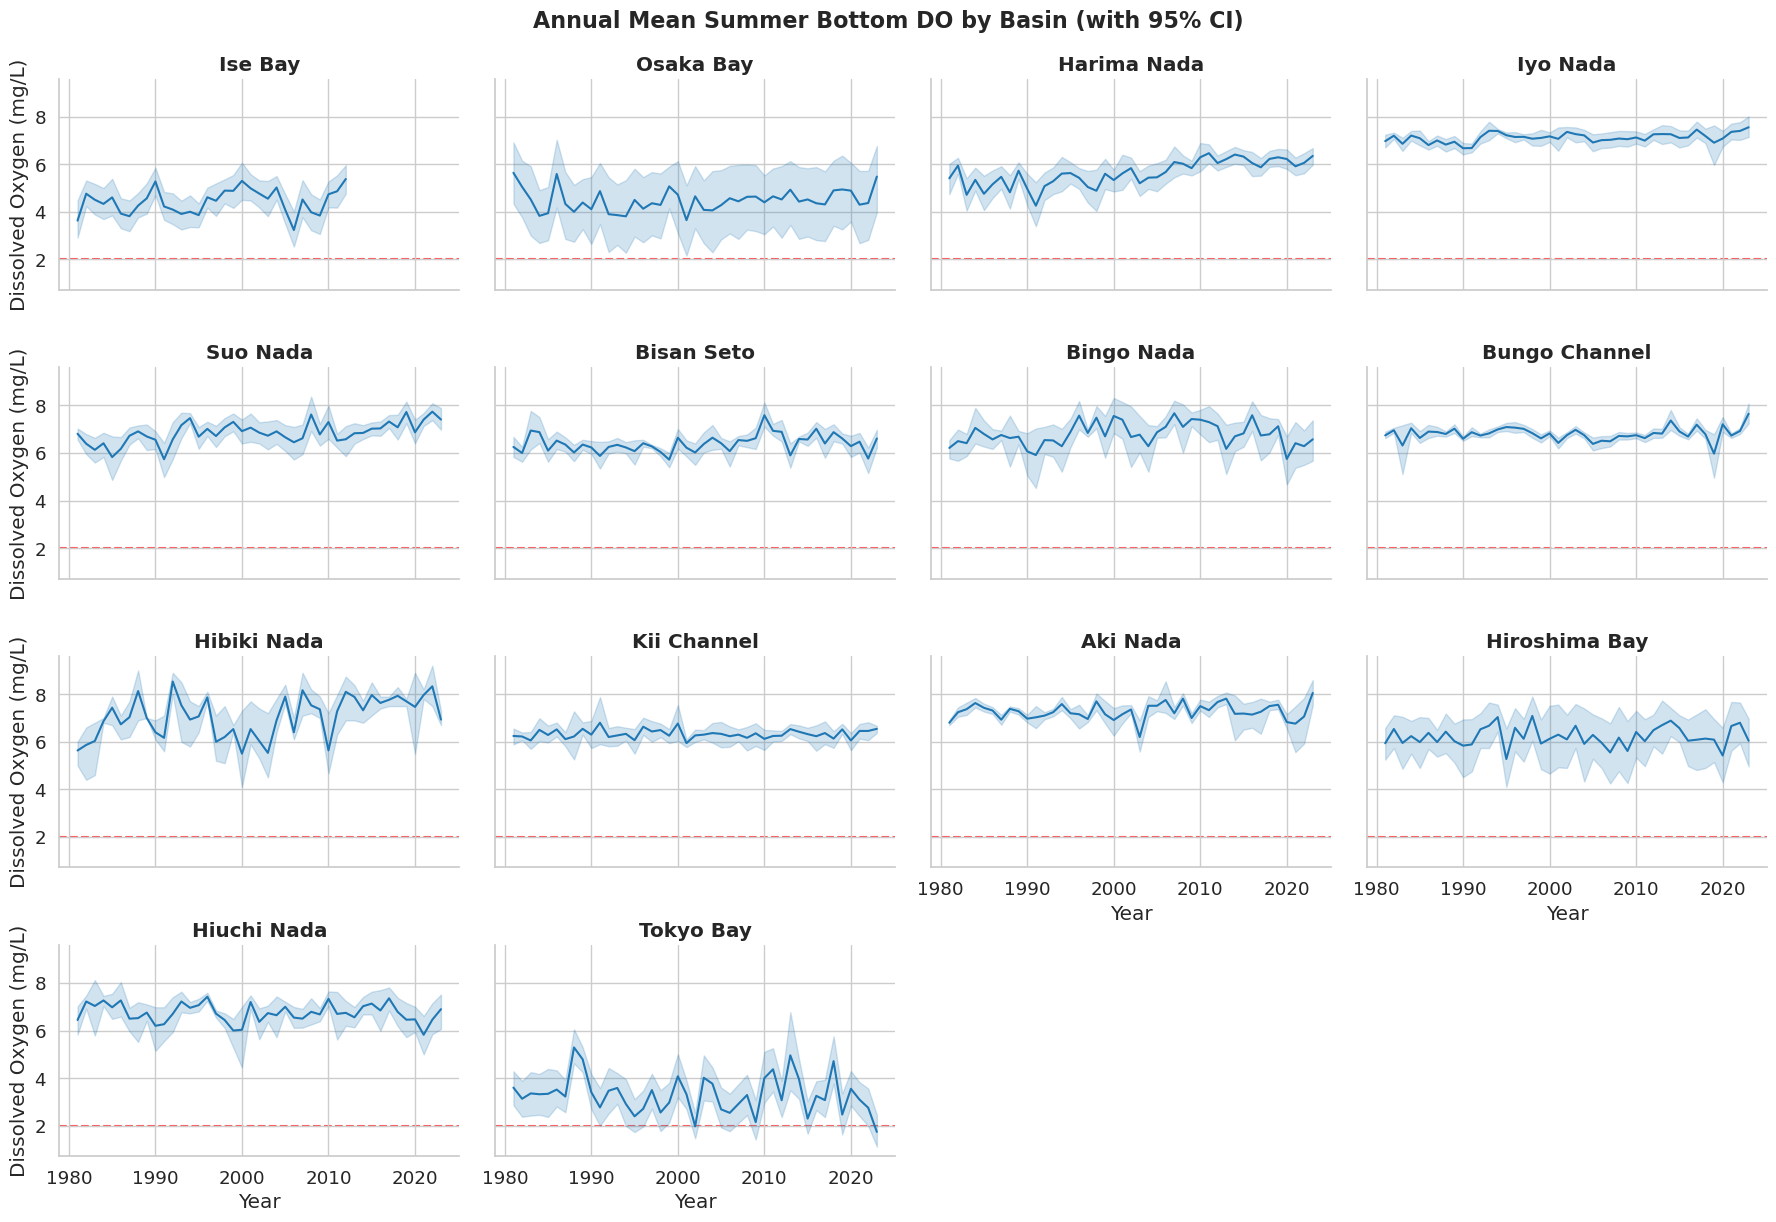

In [2]:
g = sns.relplot(
    data=summer_bottom_df, 
    x='year', y='do_', 
    col='basin', col_wrap=4, 
    kind='line', 
    height=3, aspect=1.5,
    errorbar=('ci', 95), # 95% confidence interval
    color='tab:blue' # Using a color from config
)

g.set_axis_labels("Year", "Dissolved Oxygen (mg/L)")
g.set_titles("{col_name}")

# Add a reference line for hypoxia
for ax in g.axes.flat:
    ax.axhline(2.0, color='red', linestyle='--', alpha=0.7, zorder=0)

plt.suptitle("Annual Mean Summer Bottom DO by Basin (with 95% CI)", y=1.02, fontsize=16)
plt.show()


## 2. Year vs. Basin Heatmap
A heatmap showing the mean DO for each basin across years. This is excellent for spotting specific years that were universally bad (vertical stripes) or basins that are chronically bad (horizontal stripes).


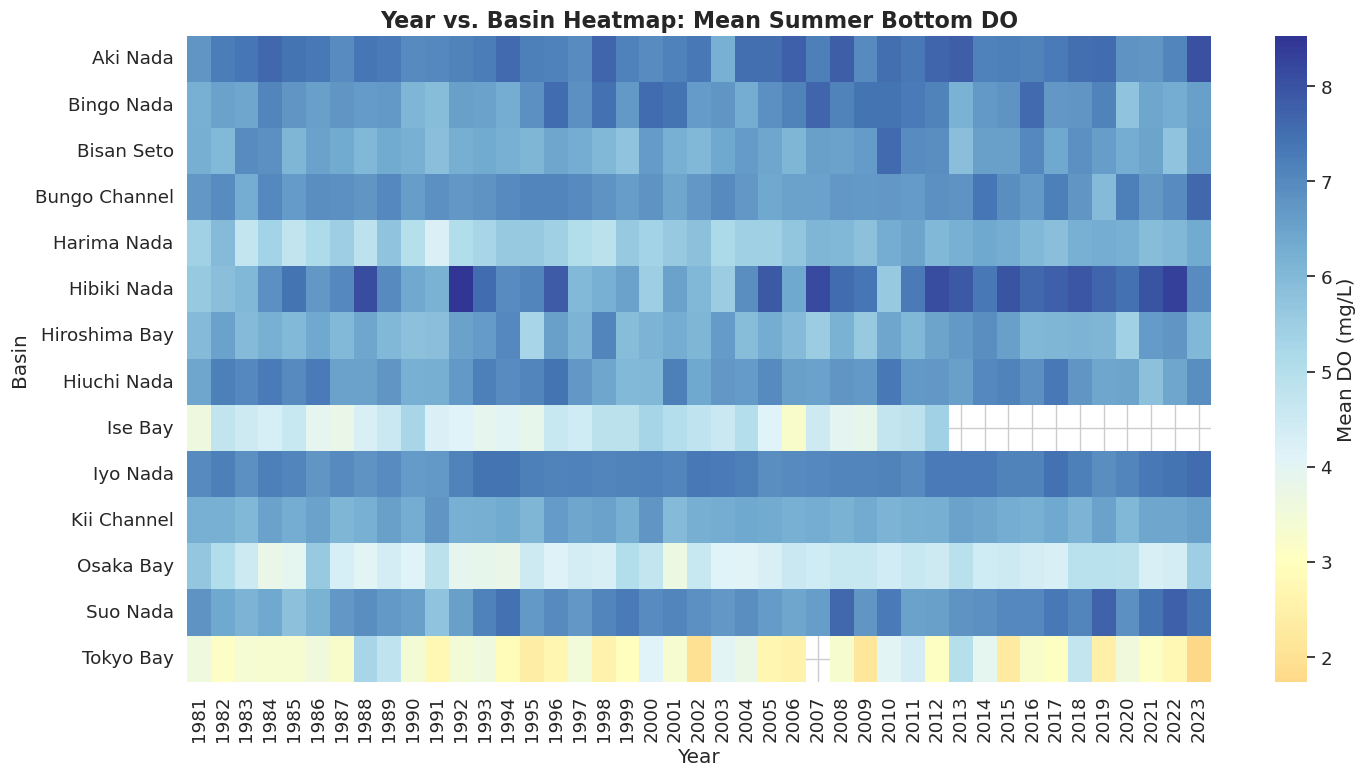

In [3]:
# Calculate mean DO per basin per year
yearly_mean_do = summer_bottom_df.groupby(['basin', 'year'])['do_'].mean().reset_index()

# Pivot for heatmap
heatmap_data = yearly_mean_do.pivot(index='basin', columns='year', values='do_')

plt.figure(figsize=(15, 8))
ax = sns.heatmap(
    heatmap_data, 
    cmap='RdYlBu', 
    center=3.0, # Center color map around a threshold (e.g., 3 mg/L)
    annot=False, 
    cbar_kws={'label': 'Mean DO (mg/L)'}
)

plt.title("Year vs. Basin Heatmap: Mean Summer Bottom DO", fontsize=16)
plt.ylabel("Basin")
plt.xlabel("Year")
plt.tight_layout()
plt.show()


## 3. Hypoxia Frequency Bar Charts over Time
Instead of looking at the mean, let's look at the *proportion* of stations in a basin that fall into different severity categories each year.


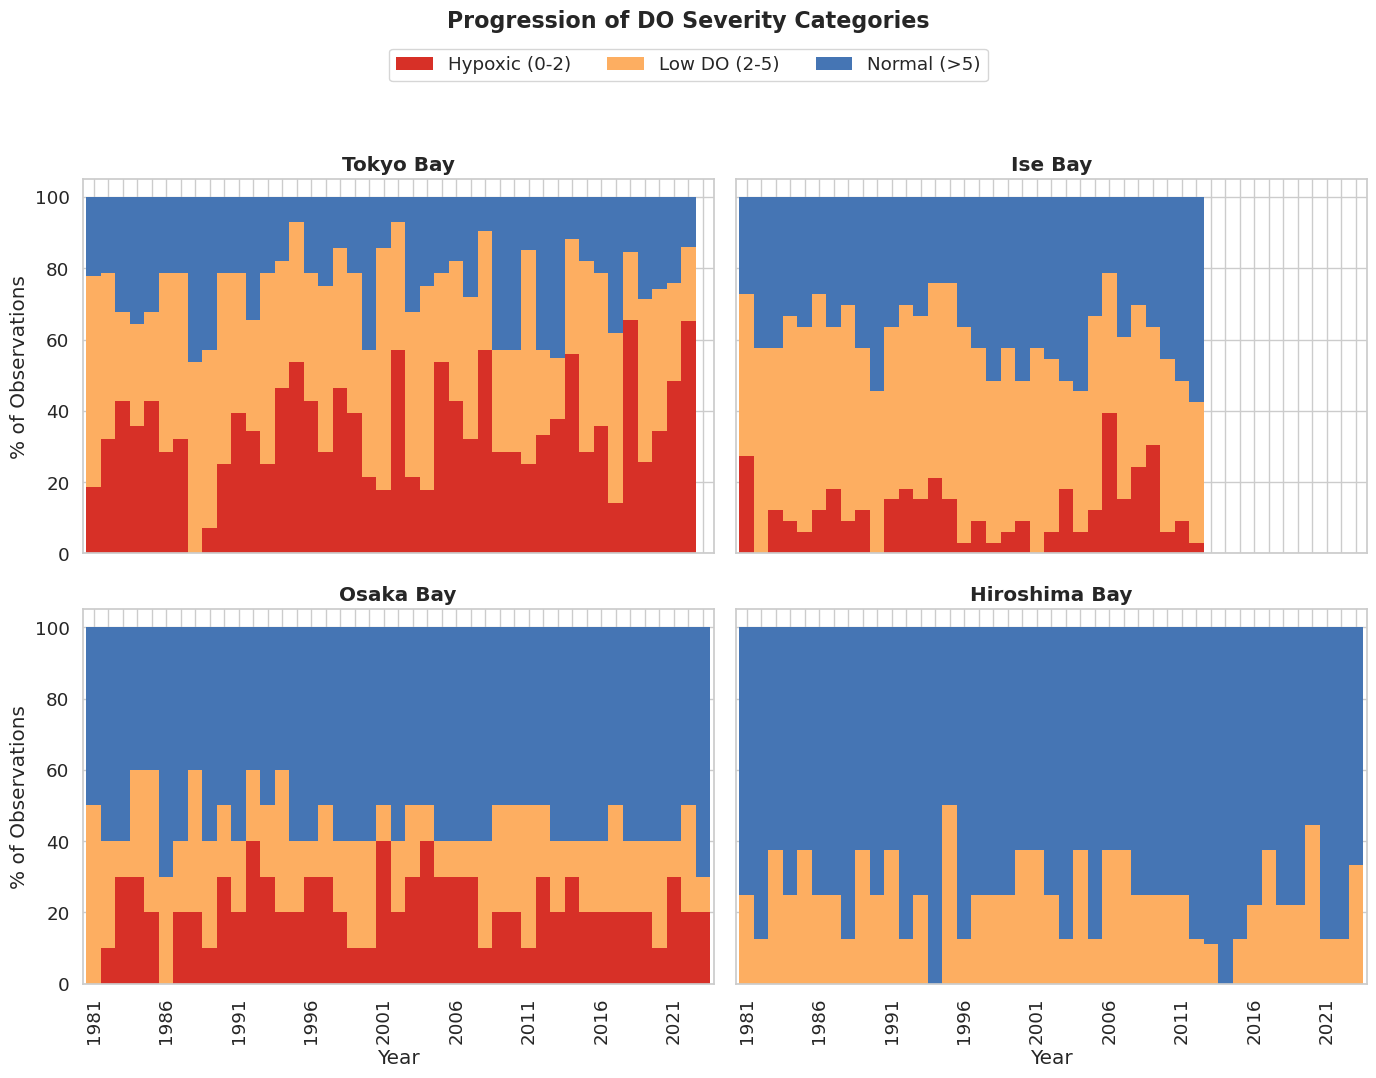

In [4]:
# Define categories
def categorize_do(val):
    if val <= 2.0:
        return 'Hypoxic (0-2)'
    elif val <= 5.0:
        return 'Low DO (2-5)'
    else:
        return 'Normal (>5)'

summer_bottom_df['do_category'] = summer_bottom_df['do_'].apply(categorize_do)

# Calculate proportions
freq_df = summer_bottom_df.groupby(['basin', 'year', 'do_category']).size().unstack(fill_value=0)
freq_df = freq_df.div(freq_df.sum(axis=1), axis=0) * 100 # Convert to percentage
freq_df = freq_df.reset_index()

# Plotting a few key basins as an example (e.g., Tokyo Bay, Ise Bay, Osaka Bay, Hiroshima Bay)
target_basins = ['Tokyo Bay', 'Ise Bay', 'Osaka Bay', 'Hiroshima Bay']
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()

colors = {'Hypoxic (0-2)': '#d73027', 'Low DO (2-5)': '#fdae61', 'Normal (>5)': '#4575b4'}

for i, basin in enumerate(target_basins):
    basin_data = freq_df[freq_df['basin'] == basin].set_index('year')
    
    # Ensure all columns exist
    for col in colors.keys():
        if col not in basin_data.columns:
            basin_data[col] = 0
            
    # Plot stacked bar
    basin_data[list(colors.keys())].plot(
        kind='bar', stacked=True, ax=axes[i], 
        color=[colors[c] for c in colors.keys()],
        width=1.0, edgecolor='none'
    )
    
    axes[i].set_title(basin)
    axes[i].set_ylabel("% of Observations")
    axes[i].set_xlabel("Year")
    
    # Clean up x-axis ticks to avoid overlapping
    for n, label in enumerate(axes[i].xaxis.get_ticklabels()):
        if n % 5 != 0:
            label.set_visible(False)

# Only keep one legend
for ax in axes:
    ax.get_legend().remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.05))

plt.suptitle("Progression of DO Severity Categories", y=1.08, fontsize=16)
plt.tight_layout()
plt.show()


## 4. Distribution of Station Trends (Violin Plots)
Calculate the trend slope (mg/L/yr) for every station, and plot the distribution of these slopes for each basin. This shows if a basin is uniformly improving/degrading, or highly variable.


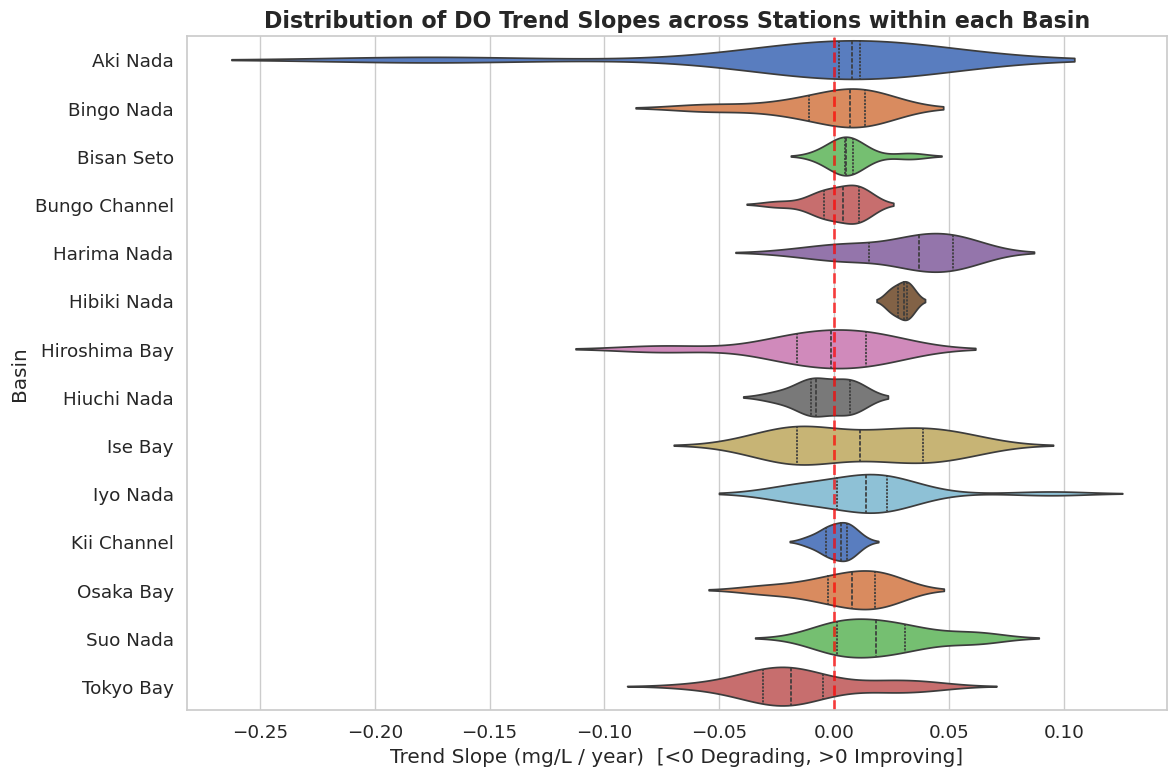

In [5]:
# Calculate slopes per station
station_slopes = []

for (basin, zettaicode), group in summer_bottom_df.groupby(['basin', 'zettaicode']):
    group = group.dropna(subset=['year', 'do_'])
    if len(group) >= 5: # Require at least 5 years
        slope, intercept, r_val, p_val, std_err = stats.linregress(group['year'], group['do_'])
        station_slopes.append({
            'basin': basin,
            'zettaicode': zettaicode,
            'slope': slope,
            'mean_do': group['do_'].mean()
        })

slopes_df = pd.DataFrame(station_slopes)

# Plot violin plot
plt.figure(figsize=(12, 8))
sns.violinplot(
    data=slopes_df, 
    x='slope', y='basin', 
    inner='quartile', 
    palette='muted',
    scale='width'
)

plt.axvline(0, color='red', linestyle='--', linewidth=2, alpha=0.7)
plt.title("Distribution of DO Trend Slopes across Stations within each Basin", fontsize=16)
plt.xlabel("Trend Slope (mg/L / year)  [<0 Degrading, >0 Improving]")
plt.ylabel("Basin")
plt.tight_layout()
plt.show()


## 5. Quadrant Scatter Plot: Mean DO vs. Trend Slope (Risk Matrix)
Scatter plot of Historical Mean DO vs. Trend Slope for each station.
- **Top Right:** Healthy & Improving
- **Bottom Right:** Warning (Okay now, but degrading)
- **Top Left:** Recovery (Historically bad, but improving)
- **Bottom Left:** Critical (Hypoxic and getting worse)


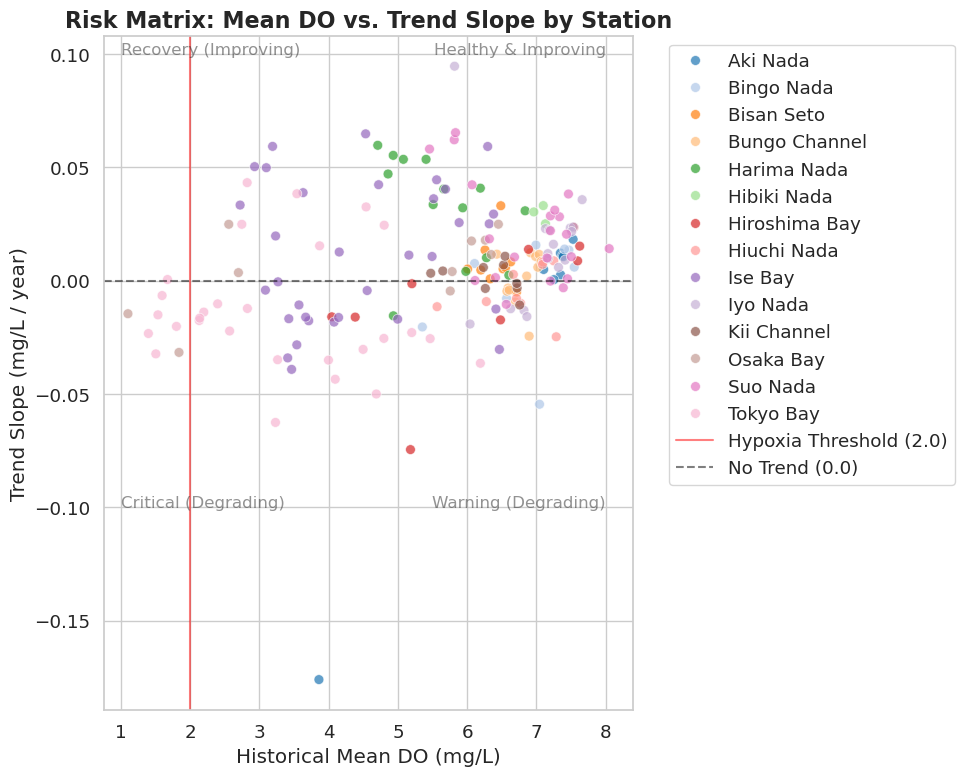

In [6]:
plt.figure(figsize=(10, 8))

# Scatter plot colored by Basin
sns.scatterplot(
    data=slopes_df,
    x='mean_do', y='slope',
    hue='basin',
    palette='tab20',
    alpha=0.7,
    s=50,
    edgecolor='w'
)

# Add quadrant lines
plt.axvline(2.0, color='red', linestyle='-', linewidth=1.5, alpha=0.5, label='Hypoxia Threshold (2.0)')
plt.axhline(0.0, color='black', linestyle='--', linewidth=1.5, alpha=0.5, label='No Trend (0.0)')

# Add annotations for quadrants
plt.text(8, 0.1, 'Healthy & Improving', fontsize=12, alpha=0.5, ha='right')
plt.text(8, -0.1, 'Warning (Degrading)', fontsize=12, alpha=0.5, ha='right')
plt.text(1, 0.1, 'Recovery (Improving)', fontsize=12, alpha=0.5, ha='left')
plt.text(1, -0.1, 'Critical (Degrading)', fontsize=12, alpha=0.5, ha='left')

plt.title("Risk Matrix: Mean DO vs. Trend Slope by Station", fontsize=16)
plt.xlabel("Historical Mean DO (mg/L)")
plt.ylabel("Trend Slope (mg/L / year)")

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 6. Decadal Boxplots
Smooth out the noise by aggregating data into decadal "epochs".


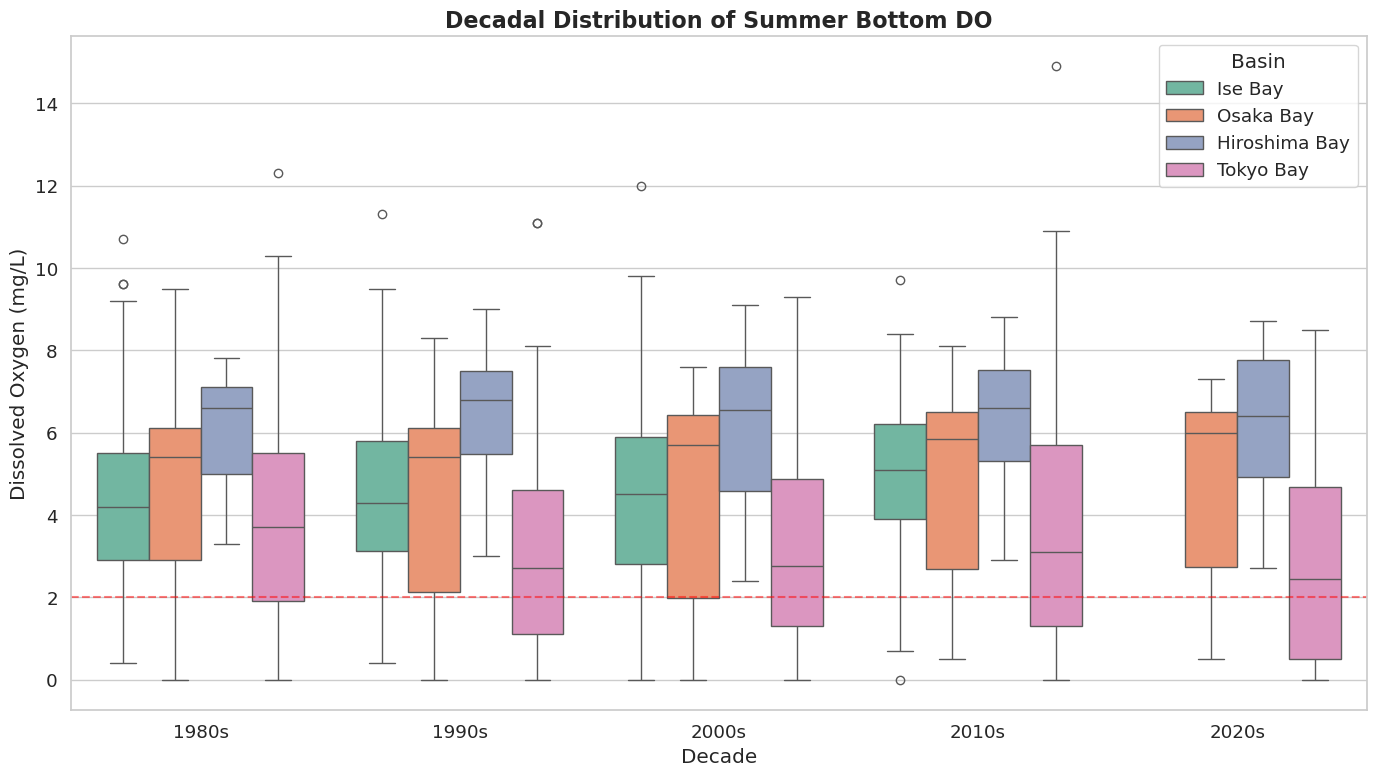

In [7]:
# Create a decade column
summer_bottom_df['decade'] = (summer_bottom_df['year'] // 10) * 10
summer_bottom_df['decade_label'] = summer_bottom_df['decade'].astype(str) + "s"

# Select a few basins to avoid overcrowding the plot
selected_basins = ['Tokyo Bay', 'Ise Bay', 'Osaka Bay', 'Hiroshima Bay']
subset_df = summer_bottom_df[summer_bottom_df['basin'].isin(selected_basins)]

plt.figure(figsize=(14, 8))
sns.boxplot(
    data=subset_df,
    x='decade_label', y='do_',
    hue='basin',
    palette='Set2'
)

plt.axhline(2.0, color='red', linestyle='--', alpha=0.5)
plt.title("Decadal Distribution of Summer Bottom DO", fontsize=16)
plt.xlabel("Decade")
plt.ylabel("Dissolved Oxygen (mg/L)")
plt.legend(title='Basin')
plt.tight_layout()
plt.show()
